In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
plt.style.use("../scripts/project.mplstyle")
runs = pd.read_csv("../results/deseq2/power_runs.csv")
runs["depth_M"] = runs["depth"].str.rstrip("M").astype(float)    # "2.5M" → 2.5
runs


,depth,n,draw,samples,n_called,tp,fp,fpr,power,precision,depth_M
0,2.5M,2,1,"ctrl_2,ctrl_6,e2_5,e2_2",254,224,14,0.001071,0.063600,0.941176,2.5
1,5M,2,1,"ctrl_2,ctrl_6,e2_5,e2_2",508,446,26,0.001989,0.126633,0.944915,5.0
2,10M,2,1,"ctrl_2,ctrl_6,e2_5,e2_2",1036,865,55,0.004208,0.245599,0.940217,10.0
3,15M,2,1,"ctrl_2,ctrl_6,e2_5,e2_2",1374,1148,76,0.005815,0.325951,0.937908,15.0
4,20M,2,1,"ctrl_2,ctrl_6,e2_5,e2_2",1608,1329,96,0.007345,0.377342,0.932632,20.0
...,...,...,...,...,...,...,...,...,...,...,...
601,5M,7,1,"ctrl_2,ctrl_6,ctrl_5,ctrl_0,ctrl_4,ctrl_1,ctrl...",3689,2679,186,0.014231,0.760647,0.935079,5.0
602,10M,7,1,"ctrl_2,ctrl_6,ctrl_5,ctrl_0,ctrl_4,ctrl_1,ctrl...",4931,3257,199,0.015226,0.924759,0.942419,10.0
603,15M,7,1,"ctrl_2,ctrl_6,ctrl_5,ctrl_0,ctrl_4,ctrl_1,ctrl...",5592,3455,195,0.014920,0.980977,0.946575,15.0
604,20M,7,1,"ctrl_2,ctrl_6,ctrl_5,ctrl_0,ctrl_4,ctrl_1,ctrl...",6115,3512,110,0.008416,0.997161,0.969630,20.0


In [2]:
summary = (runs.groupby(["n", "depth_M"]) # group by replicates and depth
               .agg(power_mean=("power", "mean"), # calculate mean and std across all 20 draws
                    power_sd=("power", "std"),
                    fpr_mean=("fpr", "mean"),
                    precision_mean=("precision", "mean"),
                    n_called_mean=("n_called", "mean"),
                    n_draws=("power", "size"))
               .reset_index())


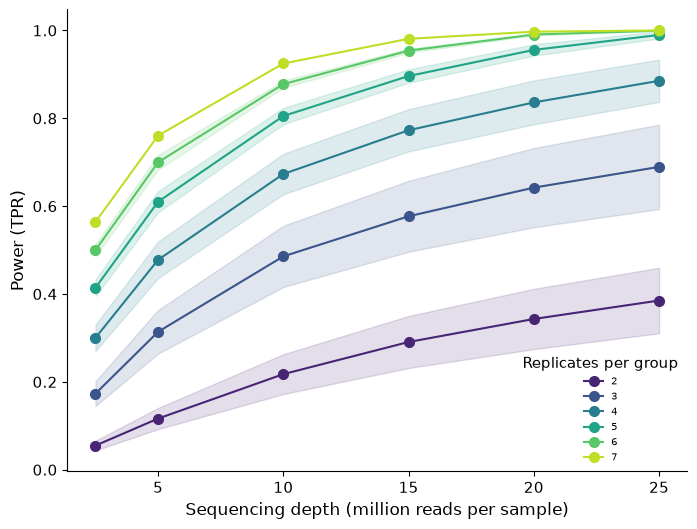

In [6]:
REP_COLORS = dict(zip(range(2, 8), plt.cm.viridis(np.linspace(0.1, 0.9, 6))))

def plot_by_reps(ax, df, x, y="power_mean", sd=None):
    for n, g in df.groupby("n"):
        g = g.sort_values(x)
        ax.plot(g[x], g[y], marker="o", color=REP_COLORS[n], label=f"{n}")
        if sd is not None:
            ax.fill_between(g[x], g[y] - g[sd], g[y] + g[sd], color=REP_COLORS[n], alpha=0.15)

fig, ax = plt.subplots(figsize=(8, 6))
plot_by_reps(ax, summary, x="depth_M", sd="power_sd")
ax.set_xlabel("Sequencing depth (million reads per sample)")
ax.set_ylabel("Power (TPR)")
ax.legend(title="Replicates per group", loc='lower right', prop={'size': 7})
fig.savefig("../results/deseq2/power_curve.png")


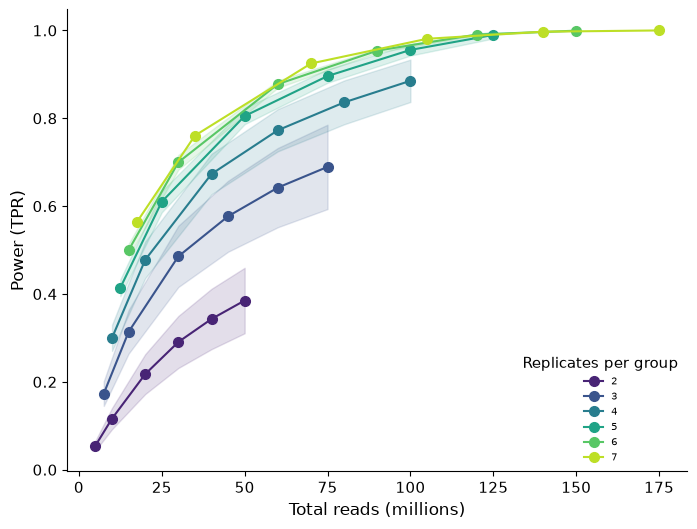

In [31]:
summary['total_reads'] = summary["n"] * summary["depth_M"]
fig, ax = plt.subplots(figsize=(8, 6))
plot_by_reps(ax, summary, x="total_reads", sd="power_sd")
ax.set_xlabel("Total reads (millions)")
ax.set_ylabel("Power (TPR)")
ax.legend(title="Replicates per group", loc='lower right', prop={'size': 7})
fig.savefig("../results/deseq2/power_vs_reads.png")


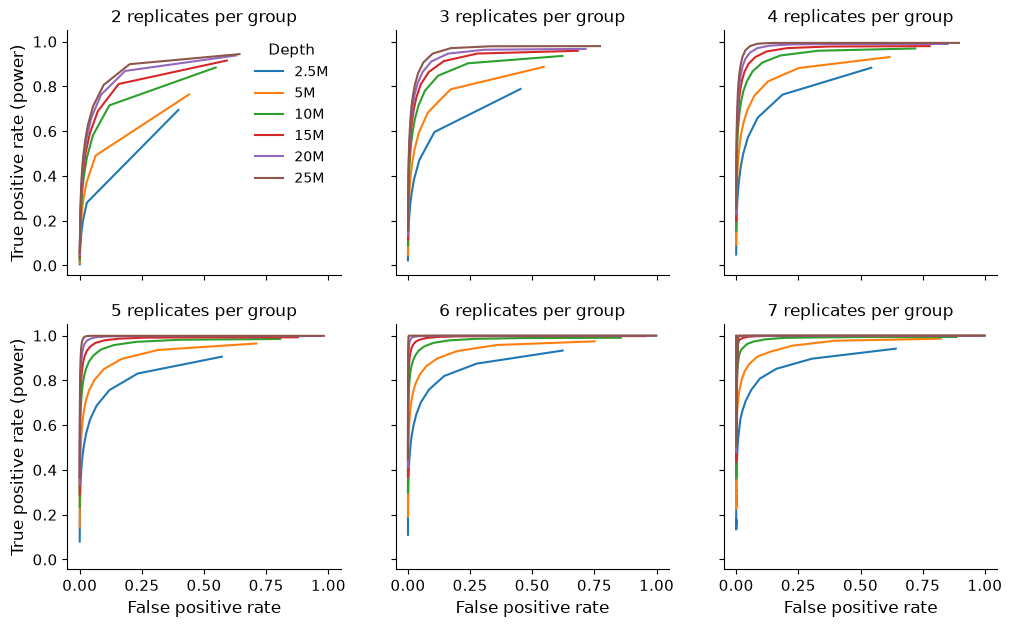

In [9]:
df = pd.read_csv("../results/deseq2/roc_runs.csv")
roc_mean = (df.groupby(["n", "depth", "threshold"])[["tpr", "fpr"]]
            .mean()
            .reset_index())

depth_order = ["2.5M", "5M", "10M", "15M", "20M", "25M"]
ns = sorted(roc_mean["n"].unique())                       # [2, 3, 4, 5, 6, 7]

fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)

for ax, n in zip(axes.flat, ns):
    sub = roc_mean[roc_mean["n"] == n]
    for depth in depth_order:
        g = sub[sub["depth"] == depth].sort_values("fpr")
        ax.plot(g["fpr"], g["tpr"], label=depth)
    ax.set_title(f"{n} replicates per group")

for ax in axes[-1]:  ax.set_xlabel("False positive rate")
for ax in axes[:, 0]: ax.set_ylabel("True positive rate (power)")
axes.flat[0].legend(title="Depth")
fig.savefig("../results/deseq2/roc_by_replicates.png")


In [10]:
LIBRARY_PREP_FIXED_COST = 198
PRICE_PER_MILLION_READS = 1.5
LIBRARY_PREP_FIXED_COST_2014 = 250
PRICE_PER_MILLION_READS_2014 = 8
summary['total_cost_2026'] = 2*summary['n']*(LIBRARY_PREP_FIXED_COST + PRICE_PER_MILLION_READS*summary['depth_M'])
summary['total_cost_2014'] = 2*summary['n']*(LIBRARY_PREP_FIXED_COST_2014 + PRICE_PER_MILLION_READS_2014*summary['depth_M'])
summary


,n,depth_M,power_mean,power_sd,fpr_mean,precision_mean,n_called_mean,n_draws,total_reads,total_cost_2026,total_cost_2014
0,2,2.5,0.055054,0.011098,0.001243,0.921530,224.90,20,5.0,807.0,1080.0
1,2,5.0,0.116496,0.024156,0.001985,0.940060,468.05,20,10.0,822.0,1160.0
2,2,10.0,0.217632,0.045363,0.003925,0.938691,891.15,20,20.0,852.0,1320.0
3,2,15.0,0.290801,0.059214,0.005593,0.934714,1210.85,20,30.0,882.0,1480.0
4,2,20.0,0.343186,0.068694,0.006806,0.934152,1441.50,20,40.0,912.0,1640.0
5,2,25.0,0.385221,0.074493,0.007181,0.937775,1618.90,20,50.0,942.0,1800.0
6,3,2.5,0.173240,0.028068,0.002953,0.941701,703.85,20,7.5,1210.5,1620.0
7,3,5.0,0.314026,0.049638,0.005406,0.941875,1310.90,20,15.0,1233.0,1740.0
8,3,10.0,0.485704,0.069768,0.008317,0.942975,2090.05,20,30.0,1278.0,1980.0
9,3,15.0,0.576973,0.080745,0.010543,0.939830,2537.05,20,45.0,1323.0,2220.0


In [11]:
def find_frontier(df, year):
    '''
    1. sort all designs by cost
    2. go  from cheapest to most expensive
    3. keep design if highest power seen
    '''
    df.sort_values(by=f"total_cost_{year}")
    df[f"on_frontier_{year}"] = df["power_mean"] > df["power_mean"].cummax().shift(fill_value=-1)

find_frontier(summary, 2014)
find_frontier(summary, 2026)


Text(0, 0.5, 'Cost (USD, 2026)')

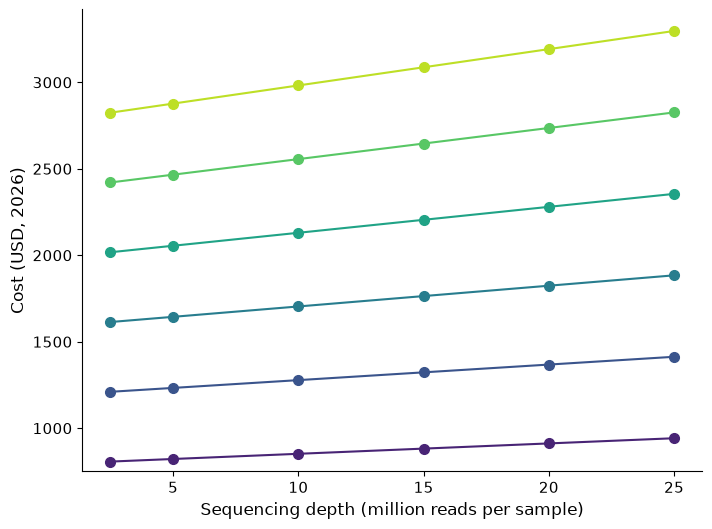

In [17]:
fig =  plt.figure(figsize=(8,6))
ax = plt.gca()

plot_by_reps(ax, summary, x="depth_M", y="total_cost_2026")

plt.ylim(bottom=750) 
ax.set_xlabel("Sequencing depth (million reads per sample)")
ax.set_ylabel("Cost (USD, 2026)")


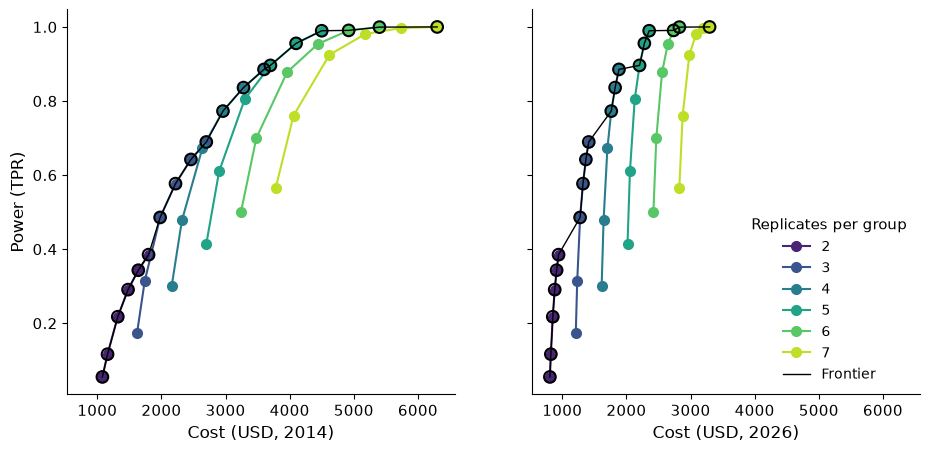

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)

# 2026 power vs cost
plot_by_reps(axes[1], summary, x="total_cost_2026", y="power_mean")
front = summary[summary["on_frontier_2026"]].sort_values("total_cost_2026")
axes[1].plot(front["total_cost_2026"], front["power_mean"],
        color="black", linewidth=1, zorder=3, label="Frontier")
axes[1].scatter(front["total_cost_2026"], front["power_mean"],
           s=70, facecolors="none", edgecolors="black", linewidths=1.5, zorder=4)

# 2014 power vs cost
plot_by_reps(axes[0], summary, x="total_cost_2014", y="power_mean")
axes[0].plot(front["total_cost_2014"], front["power_mean"],
        color="black", linewidth=1, zorder=3, label="Frontier")
axes[0].scatter(front["total_cost_2014"], front["power_mean"],
           s=70, facecolors="none", edgecolors="black", linewidths=1.5, zorder=4)

axes[0].set_xlabel("Cost (USD, 2014)")
axes[1].set_xlabel("Cost (USD, 2026)")
axes[0].set_ylabel("Power (TPR)")
axes[1].legend(title="Replicates per group", loc='lower right')
fig.savefig("../results/deseq2/power_vs_cost.png")
